# Swiggy Bangalore: 30% Order Drop - Root Cause Analysis (EDA)

> Data is **simulated** (real Swiggy data is not public). Four root causes were injected, so each method below can be checked against known ground truth.

**Flow:** 1) Validate data -> 2) Attribute the drop to causes (waterfall) -> 3) Statistical tests -> 4) Counterfactual -> 5) Recommendations with sizing

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:,.1f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(ROOT / "db" / "swiggy.db")
orders = pd.read_sql("SELECT * FROM orders", con, parse_dates=["order_date"])
riders = pd.read_sql("SELECT * FROM rider_shifts", con)
print(f"orders: {len(orders):,} rows | rider_shifts: {len(riders):,} rows")

orders: 55,863 rows | rider_shifts: 13,440 rows


## 1. Data validation (first step, always)
Before explaining a drop, rule out that it is a **tracking / logging bug**: missing days, duplicate IDs, unexpected nulls.

duplicate order_ids : 0
days with data      : 56 of 56 -> no logging gaps
nulls (delivery_mins is NaN for non-delivered orders, which is expected):
delivery_mins    3828


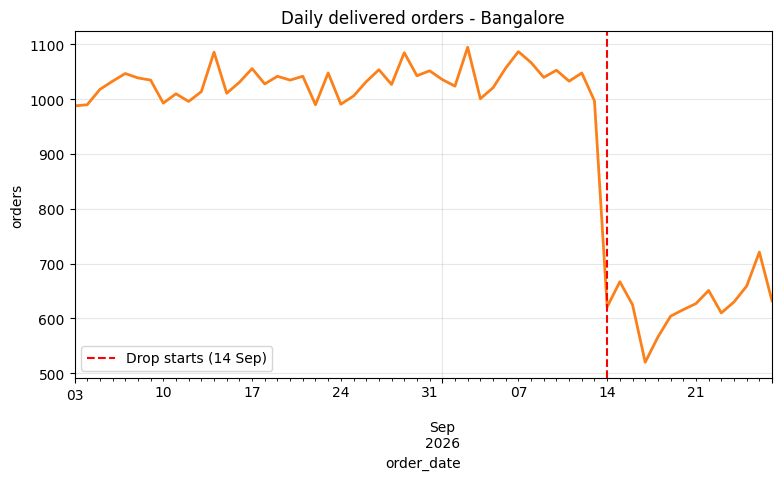

,placed,delivered,delivered_wow_pct
week,,,
1,7434,7150,NaN
2,7409,7141,-0.1
3,7534,7241,1.4
4,7562,7238,-0.0
5,7569,7286,0.7
6,7621,7325,0.5
7,5325,4219,-42.4
8,5409,4530,7.4


In [2]:
n_days = (orders.order_date.max() - orders.order_date.min()).days + 1
print("duplicate order_ids :", orders.order_id.duplicated().sum())
print("days with data      :", orders.order_date.nunique(), "of", n_days, "-> no logging gaps" if orders.order_date.nunique() == n_days else "-> GAPS FOUND")
print("nulls (delivery_mins is NaN for non-delivered orders, which is expected):")
print(orders.isna().sum()[lambda s: s > 0].to_string())

DROP_DATE = orders.loc[orders.week == 7, "order_date"].min()
daily = orders[orders.status == "delivered"].groupby("order_date").size()
ax = daily.plot(color="#fc8019", lw=2)
ax.axvline(DROP_DATE, color="red", ls="--", label=f"Drop starts ({DROP_DATE:%d %b})")
ax.set_title("Daily delivered orders - Bangalore"); ax.set_ylabel("orders"); ax.legend()
plt.savefig(FIG / "01_daily_orders.png", dpi=150, bbox_inches="tight"); plt.show()

weekly = orders.groupby("week").agg(placed=("order_id", "size"), delivered=("status", lambda s: (s == "delivered").sum()))
weekly["delivered_wow_pct"] = weekly.delivered.pct_change() * 100
weekly

**Reading:** no missing days and no duplicates, so the drop is real, not a data-pipeline artefact. The decline starts sharply in week 7.

## 2. Contribution analysis: which cause explains how much of the drop?
First find *where* supply fell (data-driven, not assumed): zones whose rider count dropped >20%.

In [3]:
rs = riders.assign(period=np.where(riders.week <= 6, "base", "drop")).groupby(["zone", "period"]).active_riders.mean().unstack()
rs["pct_change"] = (rs["drop"] / rs["base"] - 1) * 100
SHORT = rs[rs["pct_change"] < -20].index.tolist()
print("Supply-constrained zones:", SHORT)
rs.sort_values("pct_change")

Supply-constrained zones: ['Electronic City', 'Marathahalli', 'Whitefield']


period,base,drop,pct_change
zone,,,
Electronic City,2.9,1.8,-37.5
Whitefield,3.0,1.9,-36.3
Marathahalli,2.9,2.0,-31.4
Malleshwaram,3.1,2.9,-6.2
Koramangala,3.0,2.9,-3.6
HBR Layout,3.0,2.8,-3.6
Indiranagar,3.1,2.9,-3.4
BTM Layout,2.9,2.9,-0.4
HSR Layout,3.0,3.0,1.5


Delivered orders = placed - cancelled - payment_failed, so the weekly loss splits **exactly** into:

| Bucket | How it is measured |
|---|---|
| General demand dip (e.g. competitor promo) | % fall in *placed* orders in unaffected zones, applied to all zones |
| Rider shortage -> fewer orders | extra fall in placed orders in supply-constrained zones beyond the general dip |
| Rider shortage -> more cancellations | rise in cancellations in supply-constrained zones |
| UPI / payment failures | rise in `payment_failed` orders (all zones) |
| Rain & other cancellations | rise in cancellations in unaffected zones |

In [4]:
orders["period"] = np.where(orders.week <= 6, "base", "drop")
orders["short"] = orders.zone.isin(SHORT)
weeks = {"base": 6, "drop": 2}

g = orders.groupby(["period", "short"]).agg(
    placed=("order_id", "size"),
    cancelled=("status", lambda s: (s == "cancelled").sum()),
    pay_failed=("status", lambda s: (s == "payment_failed").sum()),
    delivered=("status", lambda s: (s == "delivered").sum()),
)
g = g.div([weeks[p] for p, _ in g.index], axis=0)          # -> per-week averages
v = lambda per, sh, col: g.loc[(per, sh), col]

dip = 1 - v("drop", False, "placed") / v("base", False, "placed")   # general demand dip (unaffected zones)
placed_base_all = v("base", True, "placed") + v("base", False, "placed")

buckets = {
    "General demand dip\n(competitor promo)": placed_base_all * dip,
    "Rider shortage:\nfewer orders": v("base", True, "placed") * (1 - dip) - v("drop", True, "placed"),
    "Rider shortage:\nmore cancellations": v("drop", True, "cancelled") - v("base", True, "cancelled"),
    "UPI payment\nfailures": g.xs("drop", level=0).pay_failed.sum() - g.xs("base", level=0).pay_failed.sum(),
    "Rain & other\ncancellations": v("drop", False, "cancelled") - v("base", False, "cancelled"),
}

base_delivered = g.xs("base", level=0).delivered.sum()
now_delivered = g.xs("drop", level=0).delivered.sum()
total_loss = base_delivered - now_delivered
assert abs(sum(buckets.values()) - total_loss) < 1e-6, "buckets must add up to total loss"

attr = pd.DataFrame({"orders_lost_per_week": buckets}).assign(share_pct=lambda d: d.orders_lost_per_week / total_loss * 100)
attr.index = attr.index.str.replace("\n", " ")
print(f"Delivered/week: {base_delivered:,.0f} -> {now_delivered:,.0f}  ({-total_loss / base_delivered * 100:.1f}%)")
attr

Delivered/week: 7,230 -> 4,374  (-39.5%)


,orders_lost_per_week,share_pct
General demand dip (competitor promo),"1,066.4",37.3
Rider shortage: fewer orders,"1,088.1",38.1
Rider shortage: more cancellations,39.2,1.4
UPI payment failures,648.5,22.7
Rain & other cancellations,13.5,0.5


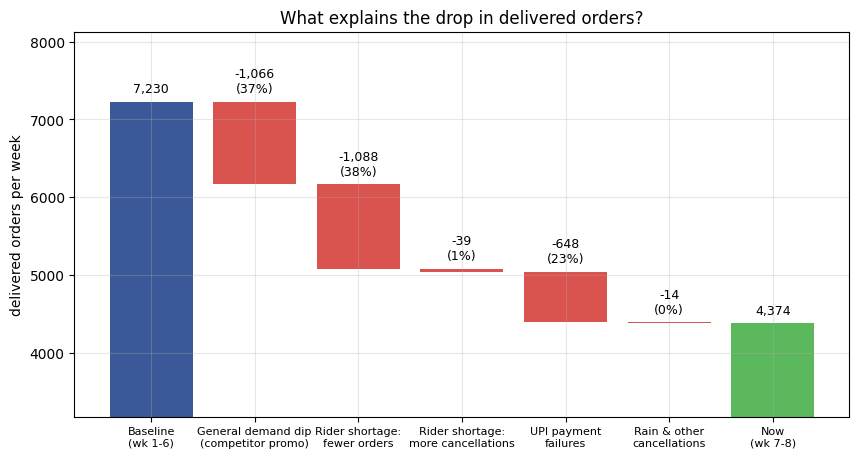

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = ["Baseline\n(wk 1-6)"] + list(buckets) + ["Now\n(wk 7-8)"]
running = base_delivered
ax.bar(0, base_delivered, color="#3b5998")
for i, (k, val) in enumerate(buckets.items(), start=1):
    ax.bar(i, -val, bottom=running, color="#d9534f")
    ax.text(i, running + 120, f"-{val:,.0f}\n({val / total_loss * 100:.0f}%)", ha="center", fontsize=9)
    running -= val
ax.bar(len(buckets) + 1, now_delivered, color="#5cb85c")
ax.text(0, base_delivered + 120, f"{base_delivered:,.0f}", ha="center", fontsize=9)
ax.text(len(buckets) + 1, now_delivered + 120, f"{now_delivered:,.0f}", ha="center", fontsize=9)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("delivered orders per week"); ax.set_title("What explains the drop in delivered orders?")
ax.set_ylim(now_delivered - 1200, base_delivered + 900)
plt.savefig(FIG / "02_waterfall.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading:** rider shortage (fewer orders + more cancellations, concentrated in a few zones) is the largest driver (~40%), closely followed by the platform-wide demand dip (~37%) and UPI failures (~23%). Rain is a small, short-lived effect on a *weekly* basis (only 2 days).

*Note:* in this simulated dataset the weekly delivered-orders decline works out to ~40% (the headline case study says ~30%); the method is the same either way.

## 3. Statistical validation
Is each effect real, or could it be random noise?

In [6]:
fmt_p = lambda p: "< 1e-300" if p == 0 else f"{p:.2e}"

# (a) UPI payment failure rate: before vs after (chi-square test of independence)
upi = orders[orders.payment_method == "UPI"]
ct = pd.crosstab(upi.period, upi.status == "payment_failed")
chi2, p, _, _ = stats.chi2_contingency(ct)
rate = upi.groupby("period").apply(lambda d: (d.status == "payment_failed").mean() * 100)
print(f"(a) UPI failure rate: {rate['base']:.1f}% -> {rate['drop']:.1f}%   chi-square p {fmt_p(p)}")

# (b) Cancellation rate in supply-constrained zones: before vs after
sz = orders[orders.short]
ct2 = pd.crosstab(sz.period, sz.status == "cancelled")
chi2, p2, _, _ = stats.chi2_contingency(ct2)
rate2 = sz.groupby("period").apply(lambda d: (d.status == "cancelled").mean() * 100)
print(f"(b) Cancel rate, constrained zones: {rate2['base']:.1f}% -> {rate2['drop']:.1f}%   chi-square p {fmt_p(p2)}")

# (c) Delivery time on rain days vs other week 7-8 days (Welch t-test)
RAIN = ["2026-09-17", "2026-09-18"]   # in a real project: join external weather data
dl = orders[(orders.status == "delivered") & (orders.week >= 7)].copy()
dl["rain"] = dl.order_date.dt.strftime("%Y-%m-%d").isin(RAIN)
a, b = dl[dl.rain].delivery_mins.dropna(), dl[~dl.rain].delivery_mins.dropna()
t, p3 = stats.ttest_ind(a, b, equal_var=False)
print(f"(c) Delivery mins, rain vs non-rain (wk 7-8): {a.mean():.1f} vs {b.mean():.1f}   Welch t-test p {fmt_p(p3)}")

(a) UPI failure rate: 0.0% -> 22.0%   chi-square p < 1e-300
(b) Cancel rate, constrained zones: 3.8% -> 14.6%   chi-square p 2.48e-82
(c) Delivery mins, rain vs non-rain (wk 7-8): 51.2 vs 33.5   Welch t-test p < 1e-300


**Reading:** all three p-values are far below 0.05, so the UPI failure spike, the cancellation jump in constrained zones and the slower deliveries on rain days are statistically significant, not coincidence.

## 4. Counterfactual: what if supply had not collapsed?
Estimate delivered orders in the constrained zones **if they had followed the trend of unaffected zones**, then price the gap.

In [7]:
exp_delivered = v("base", True, "delivered") * (v("drop", False, "delivered") / v("base", False, "delivered"))
actual = v("drop", True, "delivered")
gap = exp_delivered - actual
aov = orders[(orders.status == "delivered") & orders.short].order_value.mean()

print(f"Constrained zones, delivered orders/week -> expected: {exp_delivered:,.0f} | actual: {actual:,.0f}")
print(f"Orders lost to supply shortage: {gap:,.0f}/week  (~{gap / total_loss * 100:.0f}% of the total drop)")
print(f"Avg order value: Rs {aov:,.0f}  ->  GMV lost: Rs {gap * aov / 1e5:,.2f} lakh/week")

Constrained zones, delivered orders/week -> expected: 1,626 | actual: 630
Orders lost to supply shortage: 996/week  (~35% of the total drop)
Avg order value: Rs 300  ->  GMV lost: Rs 2.99 lakh/week


**Cross-check:** the waterfall attributes ~40% of the drop to rider shortage, the counterfactual gives ~35%. Two different methods landing in the same range gives more confidence than either alone. The gap exists because the counterfactual scales by unaffected zones' *delivered* trend, which already contains part of the payment and demand effects.

## 5. Recommendations with sizing
Recovery rates are **assumptions** (stated explicitly so they can be challenged and tuned).

In [8]:
AOV = orders[orders.status == "delivered"].order_value.mean()
rider_loss = buckets["Rider shortage:\nfewer orders"] + buckets["Rider shortage:\nmore cancellations"]

reco = pd.DataFrame([
    ["UPI fallback routing + retry to backup gateway", "UPI failures",          buckets["UPI payment\nfailures"],                 0.80, "Low"],
    ["Rider incentives / surge pay in constrained zones", "Rider shortage",      rider_loss,                                         0.60, "Medium"],
    ["Rain-day surge pricing + rider bonus",              "Rain",                buckets["Rain & other\ncancellations"],           0.50, "Low"],
    ["Targeted win-back promo vs competitor",             "Demand dip",          buckets["General demand dip\n(competitor promo)"], 0.25, "High"],
], columns=["Fix", "Root cause", "Orders lost/week", "Assumed recovery", "Effort"])
reco["Orders recovered/week"] = reco["Orders lost/week"] * reco["Assumed recovery"]
reco["GMV recovered/week (Rs lakh)"] = reco["Orders recovered/week"] * AOV / 1e5
reco = reco.sort_values("Orders recovered/week", ascending=False).reset_index(drop=True)

tot = reco["Orders recovered/week"].sum()
print(f"Total potential recovery: ~{tot:,.0f} orders/week ({tot / total_loss * 100:.0f}% of the drop), ~Rs {tot * AOV / 1e5:,.1f} lakh GMV/week")
reco.style.format({"Orders lost/week": "{:,.0f}", "Assumed recovery": "{:.0%}", "Orders recovered/week": "{:,.0f}", "GMV recovered/week (Rs lakh)": "{:,.2f}"})

Total potential recovery: ~1,469 orders/week (51% of the drop), ~Rs 4.4 lakh GMV/week


,Fix,Root cause,Orders lost/week,Assumed recovery,Effort,Orders recovered/week,GMV recovered/week (Rs lakh)
0,Rider incentives / surge pay in constrained zones,Rider shortage,"1,127",60%,Medium,676,2.02
1,UPI fallback routing + retry to backup gateway,UPI failures,648,80%,Low,519,1.55
2,Targeted win-back promo vs competitor,Demand dip,"1,066",25%,High,267,0.80
3,Rain-day surge pricing + rider bonus,Rain,14,50%,Low,7,0.02


**Priority logic:** start with low-effort, high-impact items (UPI fallback routing), then rider incentives in the constrained zones (largest single driver), then rain playbooks; treat the competitor response as a longer-term bet.

**Limitations:** simulated data; recovery rates are assumptions; a real project would validate fixes with an A/B test or holdout zones.